# Window-Length Comparison: Long-Period vs Short-Event Estimation

This notebook compares soil thermal diffusivity estimates obtained from different inverse-analysis time-window lengths. The workflow follows Sections 10.1 and 10.2 of `soil_thermal_inverse_methods_v2.ipynb`:

- **Long-period evaluation:** full analysis period from 2021-07-29 12:00 to 2021-08-12 00:00.
- **Short-event evaluation:** typhoon-event period from 2021-08-06 00:00 to 2021-08-09 00:00.
- **Window lengths:** 3 hr, 6 hr, and 12 hr.
- **Overlap:** 1 hr.
- **Inverse method:** adjoint gradient-based parameter estimation with L2 objective function and Tikhonov regularization.

The estimated parameter is the effective soil thermal diffusivity, `alpha`.

In [1]:
from pathlib import Path
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.ticker import MultipleLocator
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from soil_inverse import (
    HeatGrid,
    TikhonovRegularization,
    load_and_resample_soil_csv,
    median_time_step_seconds,
    make_window_indices,
    solve_adjoint_gradient_descent,
)

plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "Times New Roman"

alphabet = list(string.ascii_lowercase)


## 1. Analysis Parameters

The default grid and inverse settings are kept consistent with the current refined implicit-model workflow. The spatial grid can be changed by modifying `DZ_M`.

In [12]:
CSV_PATH = Path("Lupit_20210729_0812.csv")
OUTPUT_DIR = Path("00_output_figures/02_window_length")
OUTPUT_DIR.mkdir(exist_ok=True)

TEMP_COLUMNS = ["T1", "T2", "T3", "T4"]
WATER_CONTENT_COLUMNS = ["M1", "M2", "M3", "M4"]
DEPTHS_M = np.array([0.25, 0.50, 0.75, 1.00], dtype=float)

FULL_PERIOD_START = pd.Timestamp("2021-07-29 12:00")
FULL_PERIOD_END = pd.Timestamp("2021-08-12 00:00")
EVENT_PERIOD_START = pd.Timestamp("2021-08-06 00:00")
EVENT_PERIOD_END = pd.Timestamp("2021-08-09 00:00")

WINDOW_HOURS_LIST = (3.0, 6.0, 12.0)
OVERLAP_HOURS = 1.0

DZ_M = 0.05
THETA_CN = 0.5
ALPHA_INITIAL = 1.0e-6
ALPHA_BOUNDS = (1.0e-8, 1.0e-5)
WINDOW_TIKHONOV = TikhonovRegularization(beta=1.0e12, prior=1.0e-6)
SPACE_SCHEME = "central"

FORCE_RECOMPUTE = False

DETAIL_CSV = OUTPUT_DIR / "window_length_long_short_detail.csv"
SUMMARY_CSV = OUTPUT_DIR / "window_length_long_short_summary.csv"
SUMMARY_FIG = OUTPUT_DIR / "window_length_long_short_summary.jpg"
TIMESERIES_FIG = OUTPUT_DIR / "window_length_long_short_timeseries.jpg"


## 2. Load and Resample Data

Only `T1`, `T2`, `T3`, and `T4` are used for estimating soil thermal diffusivity. Soil-water-content columns are retained only for optional diagnostics in the output table.

In [13]:
times_all, obs_all_full, soil_water_content_all_full, resampled_data = load_and_resample_soil_csv(
    CSV_PATH,
    TEMP_COLUMNS,
    WATER_CONTENT_COLUMNS,
    resample_interval="10min",
)

time_mask = np.array(
    [(FULL_PERIOD_START <= pd.Timestamp(t) <= FULL_PERIOD_END) for t in times_all],
    dtype=bool,
)
if not time_mask.any():
    raise ValueError(f"No data inside full analysis period: {FULL_PERIOD_START} -> {FULL_PERIOD_END}")

times = times_all[time_mask]
obs_all = obs_all_full[time_mask]
soil_water_content_all = soil_water_content_all_full[time_mask]
dt_seconds = median_time_step_seconds(times)

print(f"data interval = {times[0]} -> {times[-1]}")
print(f"rows = {len(times)}")
print(f"dt = {dt_seconds:.0f} sec")


data interval = 2021-07-29 12:00:00 -> 2021-08-11 23:50:00
rows = 1944
dt = 600 sec


## 3. Build the Implicit Crank--Nicolson Grid

For the default setting, `dz = 0.05 m` gives five computational cells between adjacent temperature sensors. The time integration uses `theta = 0.5`, corresponding to the Crank--Nicolson scheme.

In [14]:
def cells_per_gap_from_dz(depths_m, dz_m):
    diffs = np.diff(np.asarray(depths_m, dtype=float))
    if not np.allclose(diffs, diffs[0]):
        raise ValueError("This helper expects uniformly spaced sensor depths.")
    cells_per_gap_float = diffs[0] / float(dz_m)
    cells_per_gap = int(round(cells_per_gap_float))
    if not np.isclose(cells_per_gap_float, cells_per_gap):
        raise ValueError(f"dz={dz_m} does not evenly divide sensor gap={diffs[0]}")
    return cells_per_gap

cells_per_gap = cells_per_gap_from_dz(DEPTHS_M, DZ_M)
grid = HeatGrid(
    DEPTHS_M,
    dt_seconds=dt_seconds,
    cells_per_gap=cells_per_gap,
    theta=THETA_CN,
)

print(f"implicit method = Crank-Nicolson")
print(f"theta = {grid.theta}")
print(f"dz = {DZ_M:.3f} m")
print(f"delta t = {dt_seconds:.0f} sec")
print(f"cells_per_gap = {cells_per_gap}")
print(f"n_cells = {grid.n_cells}")
print(f"n_nodes = {grid.n_cells + 1}")
print(f"r(alpha=1e-6) = {grid.r(1.0e-6):.6f}")


implicit method = Crank-Nicolson
theta = 0.5
dz = 0.050 m
delta t = 600 sec
cells_per_gap = 5
n_cells = 15
n_nodes = 16
r(alpha=1e-6) = 0.240000


## 4. Helper Functions

Each window estimates one scalar effective diffusivity `alpha`. The window center is used as the representative time of that estimate. The stride is computed from

\[
\mathrm{stride} = \mathrm{window\ length} - \mathrm{overlap}.
\]

In [15]:
def text_alphabet(handel, w, xx=0.05, yy=0.98):
    handel.text(
        xx,
        yy,
        f"({w})",
        transform=handel.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )


def make_window_indices_with_overlap(times, window_hours: float, overlap_hours: float):
    if window_hours <= 0:
        raise ValueError("window_hours must be positive")
    if overlap_hours < 0:
        raise ValueError("overlap_hours cannot be negative")
    if overlap_hours >= window_hours:
        raise ValueError("overlap_hours must be smaller than window_hours")
    stride_hours = window_hours - overlap_hours
    return make_window_indices(times, window_hours, stride_hours, min_points=4), stride_hours


def solve_window(obs_window):
    return solve_adjoint_gradient_descent(
        obs_window,
        grid,
        alpha_initial=ALPHA_INITIAL,
        bounds=ALPHA_BOUNDS,
        reg=WINDOW_TIKHONOV,
        space_scheme=SPACE_SCHEME,
    )


def summarize_rows(rows, period_label, period_start, period_end, window_hours, overlap_hours, stride_hours):
    alpha = np.array([r["alpha"] for r in rows], dtype=float)
    nit = np.array([r["nit"] for r in rows], dtype=float)
    cost = np.array([r["cost"] for r in rows], dtype=float)
    centers = [r["center"] for r in rows]
    period_hours = (pd.Timestamp(period_end) - pd.Timestamp(period_start)).total_seconds() / 3600.0
    return {
        "period_label": period_label,
        "period_start": period_start,
        "period_end": period_end,
        "period_hours": float(period_hours),
        "window_hours": float(window_hours),
        "overlap_hours": float(overlap_hours),
        "stride_hours": float(stride_hours),
        "n_windows": int(len(rows)),
        "first_center": min(centers) if centers else pd.NaT,
        "last_center": max(centers) if centers else pd.NaT,
        "mean_alpha": float(np.nanmean(alpha)) if len(alpha) else np.nan,
        "median_alpha": float(np.nanmedian(alpha)) if len(alpha) else np.nan,
        "std_alpha": float(np.nanstd(alpha, ddof=1)) if len(alpha) > 1 else np.nan,
        "min_alpha": float(np.nanmin(alpha)) if len(alpha) else np.nan,
        "max_alpha": float(np.nanmax(alpha)) if len(alpha) else np.nan,
        "mean_cost": float(np.nanmean(cost)) if len(cost) else np.nan,
        "median_cost": float(np.nanmedian(cost)) if len(cost) else np.nan,
        "mean_nit": float(np.nanmean(nit)) if len(nit) else np.nan,
        "median_nit": float(np.nanmedian(nit)) if len(nit) else np.nan,
        "inverse_method": "Adjoint gradient descent with L2 + Tikhonov",
        "space_scheme": SPACE_SCHEME,
        "dz_m": DZ_M,
        "theta": THETA_CN,
        "dt_seconds": dt_seconds,
    }


def run_period_estimation(period_label, period_start, period_end):
    period_mask = np.array(
        [(pd.Timestamp(period_start) <= pd.Timestamp(t) <= pd.Timestamp(period_end)) for t in times],
        dtype=bool,
    )
    if not period_mask.any():
        raise ValueError(f"No data for {period_label}: {period_start} -> {period_end}")

    period_times = times[period_mask]
    period_obs_all = obs_all[period_mask]
    period_m_all = soil_water_content_all[period_mask]

    detail_rows = []
    summary_rows = []

    for window_hours in WINDOW_HOURS_LIST:
        period_windows, stride_hours = make_window_indices_with_overlap(
            period_times,
            window_hours=window_hours,
            overlap_hours=OVERLAP_HOURS,
        )
        print(
            f"{period_label}: window={window_hours:.0f} hr, "
            f"overlap={OVERLAP_HOURS:.0f} hr, stride={stride_hours:.0f} hr, "
            f"n_windows={len(period_windows)}"
        )

        rows_this_window = []
        for k, idx in enumerate(period_windows):
            obs_w = period_obs_all[idx]
            if np.isnan(obs_w).any():
                continue
            center_position = len(idx) // 2
            center_index = int(idx[center_position])
            result = solve_window(obs_w)
            row = {
                "period_label": period_label,
                "period_start": pd.Timestamp(period_start),
                "period_end": pd.Timestamp(period_end),
                "window_hours": float(window_hours),
                "overlap_hours": float(OVERLAP_HOURS),
                "stride_hours": float(stride_hours),
                "window": k,
                "start": period_times[idx[0]],
                "center": period_times[center_index],
                "end": period_times[idx[-1]],
                "alpha": result["alpha"],
                "cost": result["cost"],
                "nit": result["nit"],
                "nfev": result.get("nfev", np.nan),
                "success": result.get("success", True),
                "M1": period_m_all[center_index, 0],
                "M2": period_m_all[center_index, 1],
                "M3": period_m_all[center_index, 2],
                "M4": period_m_all[center_index, 3],
                "mean_M": float(np.nanmean(period_m_all[center_index])),
                "window_mean_M": float(np.nanmean(period_m_all[idx])),
            }
            detail_rows.append(row)
            rows_this_window.append(row)

        summary_rows.append(
            summarize_rows(
                rows_this_window,
                period_label,
                period_start,
                period_end,
                window_hours,
                OVERLAP_HOURS,
                stride_hours,
            )
        )

    return detail_rows, summary_rows


## 5. Run or Load the Estimation

If the output CSV files already exist and `FORCE_RECOMPUTE = False`, the notebook loads the cached result. Set `FORCE_RECOMPUTE = True` to rerun the inverse analysis.

In [16]:
if DETAIL_CSV.exists() and SUMMARY_CSV.exists() and not FORCE_RECOMPUTE:
    detail_df = pd.read_csv(DETAIL_CSV)
    summary_df = pd.read_csv(SUMMARY_CSV)
    for col in ["period_start", "period_end", "start", "center", "end"]:
        if col in detail_df.columns:
            detail_df[col] = pd.to_datetime(detail_df[col])
    for col in ["period_start", "period_end", "first_center", "last_center"]:
        if col in summary_df.columns:
            summary_df[col] = pd.to_datetime(summary_df[col])
    print("loaded cached results:", DETAIL_CSV, SUMMARY_CSV)
else:
    all_detail_rows = []
    all_summary_rows = []
    periods = [
        ("Full period", FULL_PERIOD_START, FULL_PERIOD_END),
        ("Typhoon event", EVENT_PERIOD_START, EVENT_PERIOD_END),
    ]
    for period_label, period_start, period_end in periods:
        detail_rows, summary_rows = run_period_estimation(period_label, period_start, period_end)
        all_detail_rows.extend(detail_rows)
        all_summary_rows.extend(summary_rows)

    detail_df = pd.DataFrame(all_detail_rows)
    summary_df = pd.DataFrame(all_summary_rows)
    detail_df.to_csv(DETAIL_CSV, index=False)
    summary_df.to_csv(SUMMARY_CSV, index=False)
    print("saved detail:", DETAIL_CSV)
    print("saved summary:", SUMMARY_CSV)

print(summary_df[[
    "period_label", "period_hours", "window_hours", "overlap_hours", "stride_hours",
    "n_windows", "mean_alpha", "median_alpha", "std_alpha", "mean_nit"
]].to_string(index=False))


Full period: window=3 hr, overlap=1 hr, stride=2 hr, n_windows=161
Full period: window=6 hr, overlap=1 hr, stride=5 hr, n_windows=64
Full period: window=12 hr, overlap=1 hr, stride=11 hr, n_windows=29
Typhoon event: window=3 hr, overlap=1 hr, stride=2 hr, n_windows=35
Typhoon event: window=6 hr, overlap=1 hr, stride=5 hr, n_windows=14
Typhoon event: window=12 hr, overlap=1 hr, stride=11 hr, n_windows=6
saved detail: 00_output_figures/02_window_length/window_length_long_short_detail.csv
saved summary: 00_output_figures/02_window_length/window_length_long_short_summary.csv
 period_label  period_hours  window_hours  overlap_hours  stride_hours  n_windows   mean_alpha  median_alpha    std_alpha  mean_nit
  Full period         324.0           3.0            1.0           2.0        161 6.534079e-07  6.329247e-07 2.390427e-07  4.801242
  Full period         324.0           6.0            1.0           5.0         64 6.280904e-07  5.599312e-07 3.883714e-07  4.328125
  Full period         324.

## 6. Summary Comparison

This plot compares how the average estimated diffusivity changes with window length for the long-period and short-event analyses.

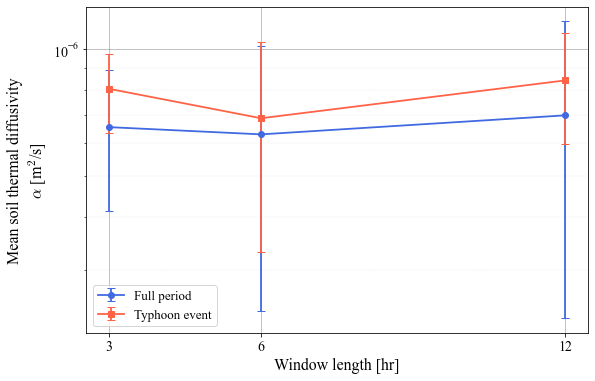

saved figure: 00_output_figures/02_window_length/window_length_long_short_summary.jpg


In [17]:
period_colors = {
    "Full period": "royalblue",
    "Typhoon event": "tomato",
}
period_markers = {
    "Full period": "o",
    "Typhoon event": "s",
}

fig_summary = plt.figure(figsize=[9, 6])
ax = fig_summary.add_subplot(1, 1, 1)

for period_label in ["Full period", "Typhoon event"]:
    subset = summary_df[summary_df["period_label"] == period_label].copy()
    subset = subset.sort_values("window_hours")
    ax.errorbar(
        subset["window_hours"],
        subset["mean_alpha"],
        yerr=subset["std_alpha"],
        color=period_colors[period_label],
        marker=period_markers[period_label],
        linewidth=1.8,
        capsize=4,
        label=period_label,
    )

ax.set_yscale("log")
ax.set_xticks(list(WINDOW_HOURS_LIST))
ax.set_xlabel("Window length [hr]", fontsize=16)
ax.set_ylabel("Mean soil thermal diffusivity\n" + r"$\alpha\,\,$[m$^2$/s]", fontsize=16)
ax.tick_params(axis="both", labelsize=14)
ax.grid(True, which="major", color="gray", alpha=0.6, linewidth=0.8)
ax.grid(True, which="minor", color="lightgray", alpha=0.5, linewidth=0.4, linestyle="--")
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
ax.yaxis.set_minor_formatter(ticker.NullFormatter())
ax.legend(loc="best", fontsize=13, facecolor="white", labelcolor="black")

fig_summary.savefig(SUMMARY_FIG, dpi=800, bbox_inches="tight")
plt.show()
print("saved figure:", SUMMARY_FIG)


## 7. Time-Series Comparison

The figure below compares long-period and short-event alpha time series using the same window-length set. Only the alpha estimates are shown, with a 2-row by 1-column layout.

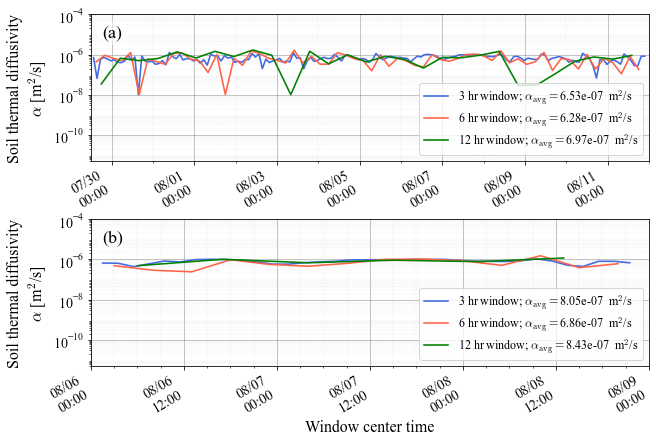

saved figure: 00_output_figures/02_window_length/window_length_long_short_timeseries.jpg


In [18]:
window_colors = {
    3.0: "royalblue",
    6.0: "tomato",
    12.0: "green",
}

fig_ts = plt.figure(figsize=[10, 14])
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.4)
spec = gridspec.GridSpec(ncols=1, nrows=4, height_ratios=[1, 1, 1, 1])


ax_full_alpha = fig_ts.add_subplot(spec[0, 0])
ax_event_alpha = fig_ts.add_subplot(spec[1, 0])

axes_by_period = {
    "Full period": ax_full_alpha,
    "Typhoon event": ax_event_alpha,
}

for period_label, ax_alpha in axes_by_period.items():
    for window_hours in WINDOW_HOURS_LIST:
        subset = detail_df[
            (detail_df["period_label"] == period_label)
            & (detail_df["window_hours"] == window_hours)
        ].copy()
        subset["center"] = pd.to_datetime(subset["center"])
        subset = subset.sort_values("center")
        if subset.empty:
            continue
        row_summary = summary_df[
            (summary_df["period_label"] == period_label)
            & (summary_df["window_hours"] == window_hours)
        ].iloc[0]
        label = (
            f"{window_hours:.0f} hr window; "
            + r"$\alpha_{\rm avg}=$"
            + f"{row_summary['mean_alpha']:.2e} " +  " m$^2$/s"
#             + r"$N_{\rm iter,avg}=$"
#             + f"{row_summary['mean_nit']:.2f}"
        )
        ax_alpha.plot(
            subset["center"],
            subset["alpha"].astype(float),
            color=window_colors[window_hours],
            linewidth=1.6,
            label=label,
        )

# ax_full_alpha.set_title("Long-period evaluation", fontsize=17)
# ax_event_alpha.set_title("Short-event evaluation", fontsize=17)

for ax_alpha in [ax_full_alpha, ax_event_alpha]:
    ax_alpha.set_yscale("log")
    ax_alpha.set_ylim(5e-12, 1e-4)
    ax_alpha.set_ylabel("Soil thermal diffusivity\n" + r"$\alpha\,\,$[m$^2$/s]", fontsize=16)
    ax_alpha.legend(loc=4, fontsize=12, facecolor="white", labelcolor="black", labelspacing=0.25)
    ax_alpha.yaxis.set_major_locator(ticker.LogLocator(base=10.0))
    ax_alpha.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax_alpha.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax_alpha.tick_params(axis="both", labelsize=14)
    ax_alpha.grid(True, which="major", color="gray", alpha=0.6, linewidth=0.8)
    ax_alpha.grid(True, which="minor", color="lightgray", alpha=0.5, linewidth=0.4, linestyle="--")

# ax_full_alpha.tick_params(axis="x", which="both", labelbottom=False)

ax_full_alpha.set_xlim(FULL_PERIOD_START, FULL_PERIOD_END)
ax_full_alpha.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax_full_alpha.xaxis.set_minor_locator(mdates.DayLocator(interval=1))
ax_full_alpha.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H:%M"))
plt.setp(ax_full_alpha.get_xticklabels(), rotation=30, ha="right")

ax_event_alpha.set_xlim(EVENT_PERIOD_START, EVENT_PERIOD_END)
ax_event_alpha.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax_event_alpha.xaxis.set_minor_locator(mdates.HourLocator(interval=3))
ax_event_alpha.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d\n%H:%M"))
ax_event_alpha.set_xlabel("Window center time", fontsize=16)
plt.setp(ax_event_alpha.get_xticklabels(), rotation=30, ha="right")

for jj, ax in enumerate([ax_full_alpha, ax_event_alpha]):
    text_alphabet(ax, alphabet[jj], xx=0.02, yy=0.93)

fig_ts.savefig(TIMESERIES_FIG, dpi=800, bbox_inches="tight")
plt.show()
print("saved figure:", TIMESERIES_FIG)
